## Project Title – Student Performance Analysis

## Introduction

The Student Performance Analysis project aims to analyse student's marks in Mathematics, Reading, and Writing.

The project uses Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn to explore the dataset, identify performance patterns, and understand how factors such as gender, test preparation, and parental education relate to students' academic performance.

The analysis also includes data cleaning, visualisation, correlation analysis, and performance classification.


## Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Student Performance Analysis")
print("All libraries imported successfully!")

Student Performance Analysis
All libraries imported successfully!


## Loading the dataset

In [2]:
# Load the dataset

df = pd.read_csv("StudentsPerformance.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Understanding Dataset

In [3]:
# Display the first five records/rows

In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
# Check the dataset dimensions

In [6]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1000
Number of Columns: 8


In [7]:
# Display column names

In [8]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [9]:
# Understand the dataset structure

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


In [11]:
# Generate statistical information

In [12]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## Data Cleaning and Preprocessing

In [13]:
# Check the missing values

In [14]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [15]:
# Check duplicate records

In [16]:
print('Total duplicate records:', df.duplicated().sum())

Total duplicate records: 0


In [17]:
# Check data types

In [18]:
df.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

In [19]:
# Check unique values in categorical columns

In [20]:
cat_col = df.select_dtypes(include='object').columns
for column in cat_col:
    print('\n', column)
    print(df[column].unique())


 gender
<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str

 race/ethnicity
<ArrowStringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

 parental level of education
<ArrowStringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

 lunch
<ArrowStringArray>
['standard', 'free/reduced']
Length: 2, dtype: str

 test preparation course
<ArrowStringArray>
['none', 'completed']
Length: 2, dtype: str


C:\Users\Harshita\AppData\Local\Temp\ipykernel_3196\2649261274.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df.select_dtypes(include='object').columns


In [21]:
# Check numerical columns

In [22]:
num_col = df.select_dtypes(include='int').columns

print('Numerical Columns:')
print(num_col.tolist())

Numerical Columns:
['math score', 'reading score', 'writing score']


In [23]:
# creating a copy of the dataset

In [24]:
cleaned_df = df.copy()

print('Working copy created successfully!')

Working copy created successfully!


In [25]:
# Check the missing values

In [26]:
print('Missing values before cleaning:')
print(cleaned_df.isnull().sum())

Missing values before cleaning:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [27]:
# Check the duplicate records

In [28]:
dup = cleaned_df.duplicated().sum()

print('Duplicate records found:', dup)

Duplicate records found: 0


In [29]:
# Verify the cleaned dataset

In [30]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", cleaned_df.shape)

Original dataset shape: (1000, 8)
Cleaned dataset shape: (1000, 8)


In [31]:
# Calculate average marks

In [32]:
score_columns = ['math score','reading score','writing score']

subject_average = cleaned_df[score_columns].mean()

print('Average marks by subject:\n', subject_average)


Average marks by subject:
 math score       66.089
reading score    69.169
writing score    68.054
dtype: float64


In [33]:
# Find the highest and lowest marks

In [34]:
print('Highest marks by subject:')
print(df[score_columns].max())

print('\nLowest marks by subject:')
print(df[score_columns].min())

Highest marks by subject:
math score       100
reading score    100
writing score    100
dtype: int64

Lowest marks by subject:
math score        0
reading score    17
writing score    10
dtype: int64


In [35]:
# Compare subject average

In [36]:
subject = ['math score','reading score','writing score']
subject_averages = df[subject].mean()

print('Average marks by subject:')
print(subject_averages)

Average marks by subject:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64


In [37]:
print('Average marks in descending order:')
print(subject_averages.sort_values(ascending=False))

Average marks in descending order:
reading score    69.169
writing score    68.054
math score       66.089
dtype: float64


## Exploratory Data Analysis (EDA)

In [38]:
# Bar Chart

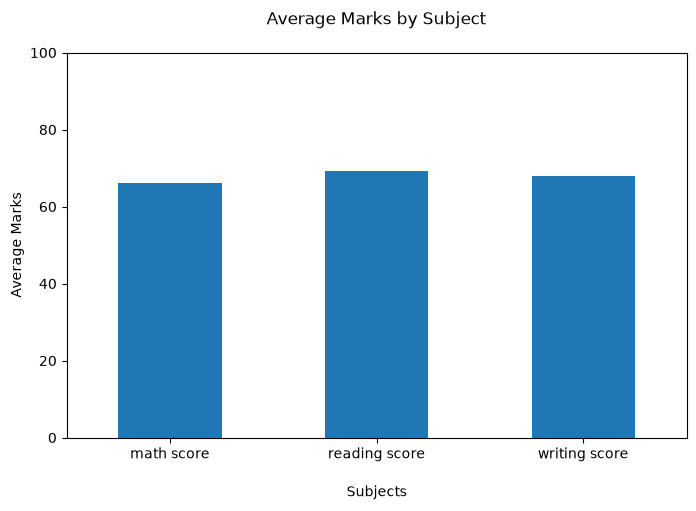

In [39]:
plt.figure(figsize=(8,5))
subject_averages.plot(kind='bar')

plt.title('Average Marks by Subject\n')
plt.xlabel('\nSubjects')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.ylim(0,100)
plt.show()

In [40]:
# Subject-wise Score Distribution

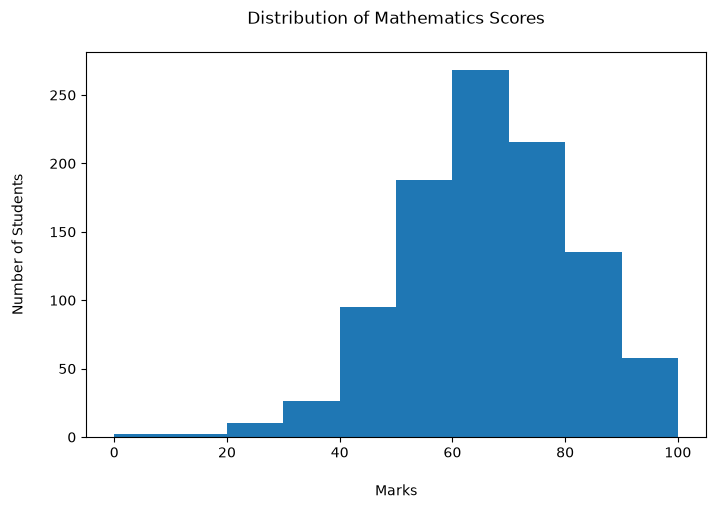

In [41]:
plt.figure(figsize=(8,5))

plt.hist(df['math score'], bins=10)

plt.title('Distribution of Mathematics Scores\n')
plt.xlabel('\nMarks')
plt.ylabel('Number of Students\n')

plt.show()

In [42]:
# Compare Score Distributions
'''
A boxplot helps us understand:

Median: The middle score.
Box: The middle 50% of scores.
Whiskers: The spread of typical scores.
Dots outside the whiskers: Potential outliers.
'''

'\nA boxplot helps us understand:\n\nMedian: The middle score.\nBox: The middle 50% of scores.\nWhiskers: The spread of typical scores.\nDots outside the whiskers: Potential outliers.\n'

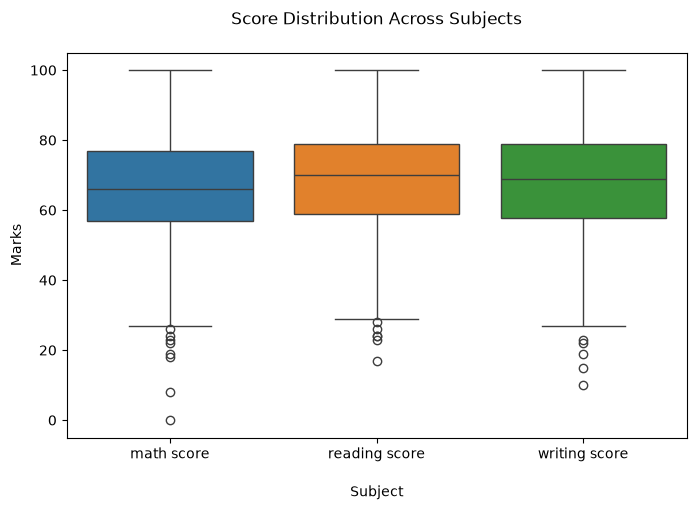

In [43]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df[score_columns])

plt.title('Score Distribution Across Subjects\n')
plt.xlabel('\nSubject')
plt.ylabel('Marks')

plt.show()

In [44]:
# Analyze Gender-wise Performance

In [45]:
gender_performance = df.groupby('gender')[score_columns].mean()

print('Average marks by gender:')
print(gender_performance)

Average marks by gender:
        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


In [46]:
# Gender-wise Performance Bar Chart

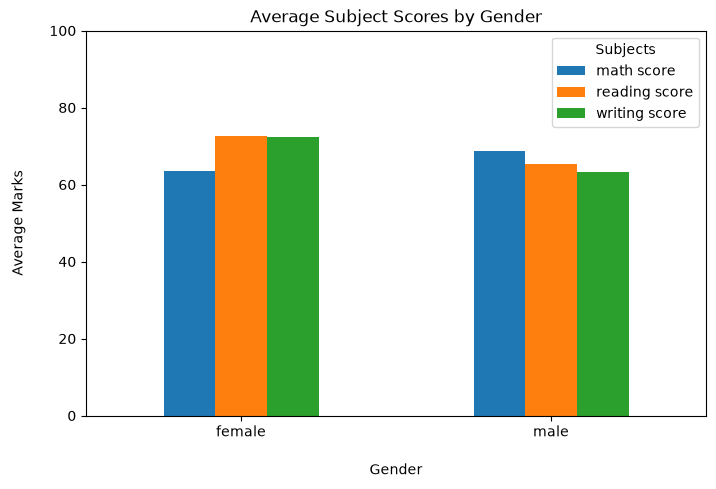

In [47]:
gender_performance.plot(kind='bar', figsize=(8,5))

plt.title("Average Subject Scores by Gender")
plt.xlabel("\nGender")
plt.ylabel('Average Marks\n')
plt.xticks(rotation=0)
plt.ylim(0,100)
plt.legend(title='Subjects')

plt.show()

In [48]:
# Test Preparation vs Student Performance

In [49]:
preparation_performance = df.groupby('test preparation course')[score_columns].mean()

print('Average marks based on test preparation:')
print(preparation_performance)

Average marks based on test preparation:
                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


In [50]:
# Test Preparation Performance Visualization

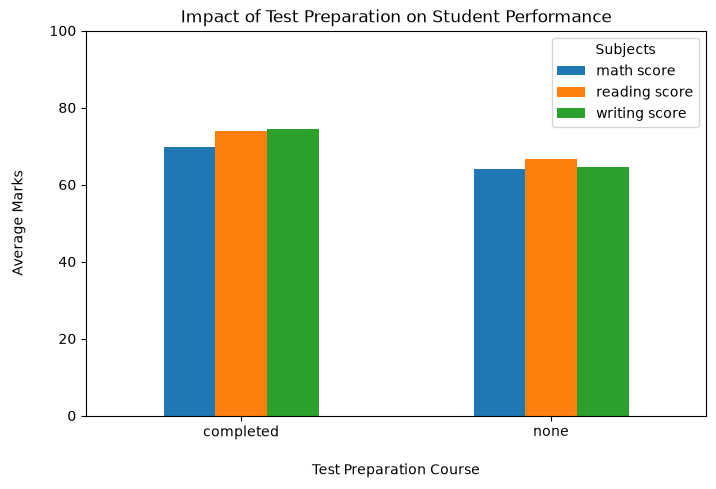

In [53]:
preparation_performance.plot(kind='bar',figsize=(8,5))

plt.title('Impact of Test Preparation on Student Performance')
plt.xlabel('\nTest Preparation Course')
plt.ylabel('Average Marks\n')
plt.xticks(rotation=0)
plt.ylim(0,100)
plt.legend(title='Subjects')

plt.show()

## Correlation Analysis

In [54]:
# Calculate Correlation Between Subjects

In [55]:
correlation = df[score_columns].corr()

print('Correlation between subjects:')
print(correlation)

Correlation between subjects:
               math score  reading score  writing score
math score       1.000000       0.817580       0.802642
reading score    0.817580       1.000000       0.954598
writing score    0.802642       0.954598       1.000000


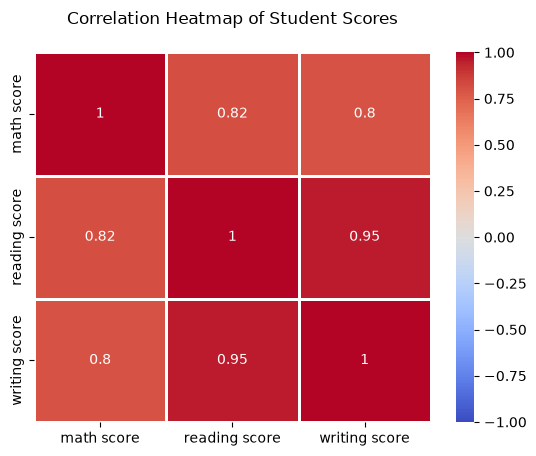

In [65]:
#plt.figure(figsize=(8,5))

sns.heatmap(correlation,annot=True,cmap='coolwarm',linewidths=1,vmin=-1,vmax=1)
plt.title("Correlation Heatmap of Student Scores\n")

plt.show()

### Interpretation

* Mathematics and Reading have a strong positive correlation (0.82).
* Mathematics and Writing have a strong positive correlation (0.80).
* Reading and Writing have a very strong positive correlation (0.95).
* Reading and Writing scores show the strongest relationship.

This indicates that students who score higher in one subject tend to score higher in the other related subjects. However, correlation does not prove causation.


## Parental Education Analysis

In [66]:
# Parental Education VS Student Performance

In [69]:
parent_education_performance = df.groupby('parental level of education')[score_columns].mean()

print('Average marks based on parental education:')
print(parent_education_performance)

Average marks based on parental education:
                             math score  reading score  writing score
parental level of education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.381356
high school                   62.137755      64.704082      62.448980
master's degree               69.745763      75.372881      75.677966
some college                  67.128319      69.460177      68.840708
some high school              63.497207      66.938547      64.888268


In [70]:
#Parental Education Performance Chart

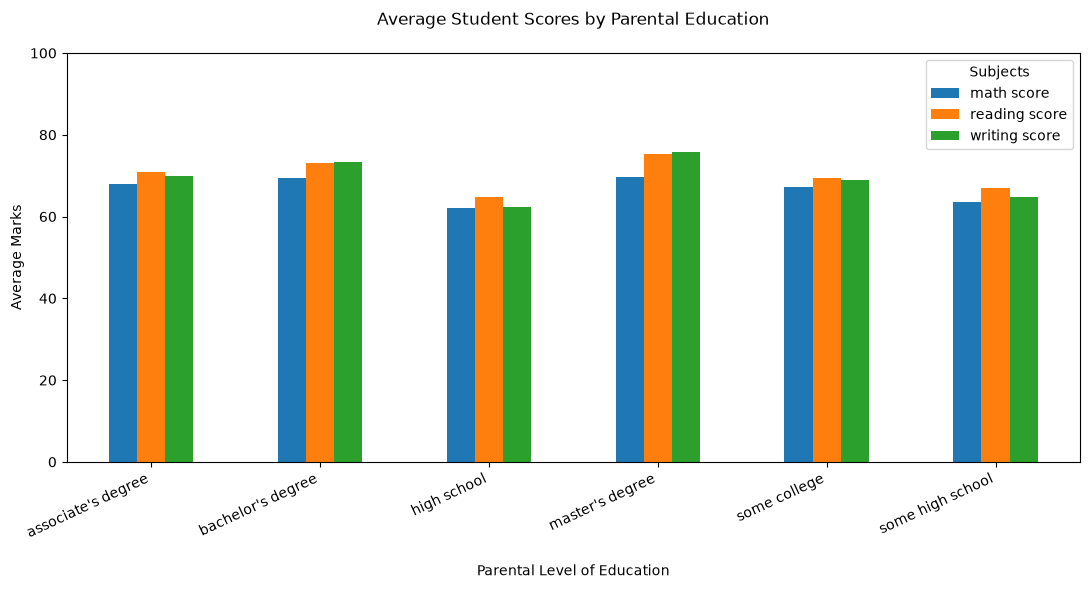

In [76]:
parent_education_performance.plot(kind='bar',figsize=(11,6))

plt.title('Average Student Scores by Parental Education\n')
plt.xlabel('\nParental Level of Education')
plt.ylabel('Average Marks')
plt.xticks(rotation=25, ha='right')
plt.ylim(0,100)
plt.legend(title='Subjects')
plt.tight_layout()

plt.show()

In [77]:
# Calculate Overall Student Performance

In [78]:
df["average score"] = df[score_columns].mean(axis=1)

print("Student performance:")
print(df[["math score", "reading score", "writing score", "average score"]].head())

Student performance:
   math score  reading score  writing score  average score
0          72             72             74      72.666667
1          69             90             88      82.333333
2          90             95             93      92.666667
3          47             57             44      49.333333
4          76             78             75      76.333333


In [79]:
# Student Performance Classification

In [80]:
def classify_performance(score):
    if score >= 75:
        return "Excellent"
    elif score >= 60:
        return "Good"
    elif score >= 40:
        return "Average"
    else:
        return "Needs Improvement"


df["performance category"] = df["average score"].apply(classify_performance)

print("Student performance categories:")
print(df[["average score", "performance category"]].head(10))

Student performance categories:
   average score performance category
0      72.666667                 Good
1      82.333333            Excellent
2      92.666667            Excellent
3      49.333333              Average
4      76.333333            Excellent
5      77.333333            Excellent
6      91.666667            Excellent
7      40.666667              Average
8      65.000000                 Good
9      49.333333              Average


In [81]:
# Count Students in Each Performance Category

In [83]:
performance_counts = df["performance category"].value_counts()

print("Number of students in each performance category:")
print(performance_counts)

Number of students in each performance category:
performance category
Good                 391
Excellent            324
Average              255
Needs Improvement     30
Name: count, dtype: int64


In [84]:
# Performance Distribution Chart

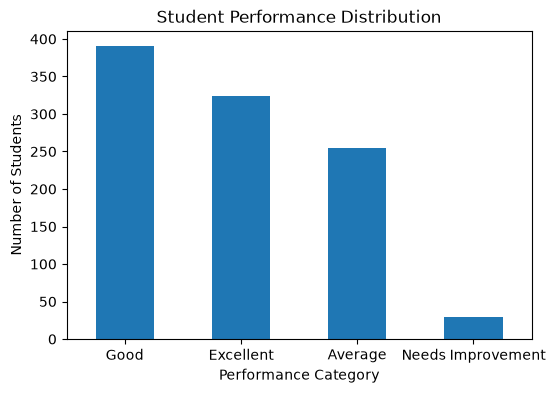

In [87]:
plt.figure(figsize=(6, 4))

performance_counts.plot(kind="bar")

plt.title("Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.show()

## Final Observations

In [88]:
# Generate an analysis summary

In [89]:
print("========== STUDENT PERFORMANCE ANALYSIS ==========")

print("\n1. Average Marks by Subject:")
print(subject_averages)

print("\n2. Gender-wise Performance:")
print(gender_performance)

print("\n3. Test Preparation Performance:")
print(preparation_performance)

print("\n4. Parental Education Performance:")
print(parent_education_performance)

print("\n5. Student Performance Categories:")
print(performance_counts)

print("\n6. Subject Correlation:")
print(correlation)

========== STUDENT PERFORMANCE ANALYSIS ==========

1. Average Marks by Subject:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

2. Gender-wise Performance:
        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203

3. Test Preparation Performance:
                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673

4. Parental Education Performance:
                             math score  reading score  writing score
parental level of education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.

## Conclusion

The Student Performance Analysis project helped identify patterns in student's academic performance using Python.

The analysis showed that Reading had the highest average score, while Mathematics had the lowest. Students who completed the test preparation course achieved higher average scores in all three subjects. The analysis also identified differences in subject performance across gender and parental education groups.

The correlation analysis showed a strong positive relationship between Reading and Writing scores.

Overall, this project provided practical experience in data cleaning, data analysis, data visualisation, and interpreting insights from a real-world dataset.
